# Task 6 - Music Genre Classification
**Elevvo ML Internship - Level 3**

Goal: classify songs into 10 genres from audio features (MFCCs, spectral features, tempo) extracted with Librosa, and compare several multi-class models.

Dataset: [GTZAN (Kaggle)](https://www.kaggle.com/datasets/andradaolteanu/gtzan-dataset-music-genre-classification) - this notebook uses the dataset's pre-extracted feature files `features_3_sec.csv` and `features_30_sec.csv`. Put them in the same folder as this notebook (in Colab, upload them with the Files panel).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

In [2]:
from rich.console import Console
from rich.table import Table
from rich.panel import Panel
from rich import box

console = Console()
GREEN, CYAN, AMBER = '#33ff66', '#00e5ff', '#ffb000'
BORDER = '#15803d'  # darker green so borders stay visible on light backgrounds (e.g. GitHub)
PALETTE = [GREEN, CYAN, AMBER, '#ff4fd8', '#b388ff', '#ff6e6e', '#ffffff']

plt.style.use('dark_background')
plt.rcParams.update({
    'font.family': 'monospace', 'axes.edgecolor': GREEN, 'axes.labelcolor': GREEN,
    'xtick.color': GREEN, 'ytick.color': GREEN, 'axes.titlecolor': GREEN,
    'axes.grid': True, 'grid.color': '#1f3d1f', 'grid.linestyle': ':',
})

def term_table(df, title, index=True):
    t = Table(title=f'> {title}', title_justify='left', title_style=f'bold {GREEN}',
              box=box.SQUARE, border_style=BORDER, header_style=f'bold {CYAN}')
    if index:
        t.add_column(str(df.index.name or ''), style=AMBER)
    for col in df.columns:
        t.add_column(str(col), justify='right', style=GREEN)
    for idx, *row in df.itertuples():
        values = [f'{v:,.3f}' if isinstance(v, float) else str(v) for v in row]
        t.add_row(*([str(idx)] if index else []), *values)
    console.print(t)

def term_panel(title, lines):
    body = '\n'.join(f'[{GREEN}]$[/] {line}' for line in lines)
    console.print(Panel(body, title=f'[bold {GREEN}]{title}', title_align='left',
                        border_style=BORDER, box=box.SQUARE, expand=False))

## 1. Load and explore the data
Each of the 1,000 songs (30 seconds, 100 per genre) is cut into ten 3-second clips, and every clip has 57 audio features: chroma, RMS energy, spectral centroid/bandwidth/rolloff, zero-crossing rate, harmony, percussiveness, tempo and 20 MFCCs (mean and variance).

In [3]:
df = pd.read_csv('features_3_sec.csv')
df['song'] = df['filename'].str.rsplit('.', n=2).str[0]  # 'blues.00000.3.wav' -> 'blues.00000'

term_panel('DATASET LOADED', [f'clips    : {len(df):,}', f'songs    : {df.song.nunique():,}',
                              f'features : {df.shape[1] - 4}', f'genres   : {df.label.nunique()}',
                              f'missing  : {df.isnull().sum().sum()}'])
term_table(df['label'].value_counts().to_frame('clips'), 'CLIPS PER GENRE')

┌─ DATASET LOADED ───┐
│ $ clips    : 9,990 │
│ $ songs    : 1,000 │
│ $ features : 57    │
│ $ genres   : 10    │
│ $ missing  : 0     │
└────────────────────┘

> CLIPS PER GENRE    
┌───────────┬───────┐
│ label     │ clips │
├───────────┼───────┤
│ blues     │  1000 │
│ jazz      │  1000 │
│ metal     │  1000 │
│ pop       │  1000 │
│ reggae    │  1000 │
│ disco     │   999 │
│ classical │   998 │
│ hiphop    │   998 │
│ rock      │   998 │
│ country   │   997 │
└───────────┴───────┘

## 2. Visual exploration

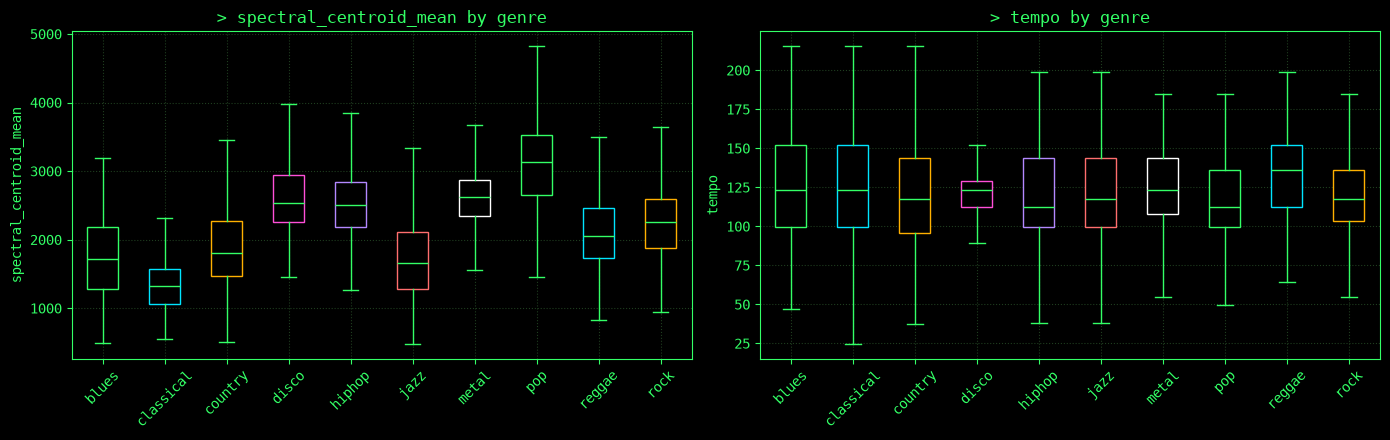

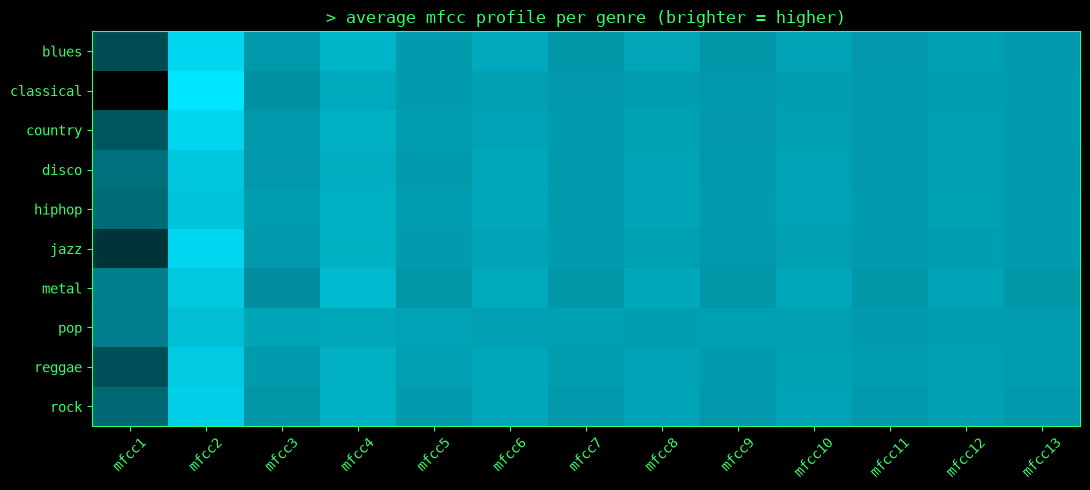

In [4]:
genres = sorted(df['label'].unique())
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, feature in zip(axes, ['spectral_centroid_mean', 'tempo']):
    data = [df.loc[df.label == g, feature] for g in genres]
    bp = ax.boxplot(data, patch_artist=True, showfliers=False)
    for patch, color in zip(bp['boxes'], PALETTE * 2):
        patch.set(facecolor='black', edgecolor=color)
    for part in ['whiskers', 'caps', 'medians']:
        plt.setp(bp[part], color=GREEN)
    ax.set_xticks(range(1, len(genres) + 1), genres, rotation=45)
    ax.set(title=f'> {feature} by genre', ylabel=feature)
plt.tight_layout()
plt.show()

mfcc_means = df.groupby('label')[[f'mfcc{i}_mean' for i in range(1, 14)]].mean()
fig, ax = plt.subplots(figsize=(11, 5))
ax.imshow(mfcc_means, aspect='auto', cmap=LinearSegmentedColormap.from_list('t', ['#000000', CYAN]))
ax.grid(False)
ax.set_yticks(range(len(genres)), mfcc_means.index)
ax.set_xticks(range(13), [f'mfcc{i}' for i in range(1, 14)], rotation=45)
ax.set(title='> average mfcc profile per genre (brighter = higher)')
plt.tight_layout()
plt.show()

## 3. Preprocessing and train / test split
Clips from the same song sound alike. If some clips of a song are in training and others in testing, the model can recognise the *song* instead of the *genre*, which inflates accuracy. So the split is done **by song**: 80% of songs for training, 20% for testing. Features are then standardized.

In [5]:
feature_cols = [c for c in df.columns if c not in ('filename', 'length', 'label', 'song')]
X = df[feature_cols]
encoder = LabelEncoder()
y = encoder.fit_transform(df['label'])

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups=df['song']))
X_train, X_test, y_train, y_test = X.iloc[train_idx], X.iloc[test_idx], y[train_idx], y[test_idx]

overlap = set(df.song.iloc[train_idx]) & set(df.song.iloc[test_idx])
term_panel('TRAIN / TEST SPLIT (BY SONG)', [f'train : {len(X_train):,} clips from {df.song.iloc[train_idx].nunique()} songs',
                                           f'test  : {len(X_test):,} clips from {df.song.iloc[test_idx].nunique()} songs',
                                           f'songs in both sets : {len(overlap)}'])

┌─ TRAIN / TEST SPLIT (BY SONG) ───────┐
│ $ train : 7,993 clips from 800 songs │
│ $ test  : 1,997 clips from 200 songs │
│ $ songs in both sets : 0             │
└──────────────────────────────────────┘

## 4. Train and compare models
Three multi-class models, each with feature scaling built into a pipeline:
- **Random Forest**: an ensemble of decision trees
- **SVM** (RBF kernel): finds boundaries between genres in feature space
- **Neural network** (MLP, 2 hidden layers): a small fully-connected network

In [6]:
models = {
    'Random Forest': make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=42)),
    'SVM (RBF)': make_pipeline(StandardScaler(), SVC(C=10, gamma='scale')),
    'Neural network (MLP)': make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(256, 128), alpha=1e-3,
                                                                   early_stopping=True, max_iter=500, random_state=42)),
}

results, predictions = {}, {}
for name, model in models.items():
    pred = model.fit(X_train, y_train).predict(X_test)
    predictions[name] = pred
    results[name] = {'accuracy': accuracy_score(y_test, pred), 'macro F1': f1_score(y_test, pred, average='macro')}

results_df = pd.DataFrame(results).T.sort_values('accuracy', ascending=False)
best_name = results_df.index[0]
term_table(results_df, 'MODEL COMPARISON (3-SEC CLIPS, TEST SET)')

> MODEL COMPARISON (3-SEC CLIPS, TEST SET)    
┌──────────────────────┬──────────┬──────────┐
│                      │ accuracy │ macro F1 │
├──────────────────────┼──────────┼──────────┤
│ SVM (RBF)            │    0.708 │    0.699 │
│ Random Forest        │    0.690 │    0.689 │
│ Neural network (MLP) │    0.685 │    0.682 │
└──────────────────────┴──────────┴──────────┘

## 5. From clips to songs: majority vote
A real song is longer than 3 seconds. Predicting each clip and taking the most common genre across the song's clips gives a song-level prediction.

In [7]:
test_songs = df.iloc[test_idx][['song']].assign(true=y_test, pred=predictions[best_name])
votes = test_songs.groupby('song').agg(true=('true', 'first'), pred=('pred', lambda p: p.mode()[0]))
song_acc = (votes.true == votes.pred).mean()
term_panel(f'SONG-LEVEL ACCURACY: {best_name.upper()}', [f'clip accuracy : {results_df.loc[best_name, "accuracy"]:.3f}',
                                                      f'song accuracy : {song_acc:.3f}  ({len(votes)} test songs)'])

┌─ SONG-LEVEL ACCURACY: SVM (RBF) ──────────┐
│ $ clip accuracy : 0.708                   │
│ $ song accuracy : 0.775  (200 test songs) │
└───────────────────────────────────────────┘

## 6. Confusion matrix (best model)

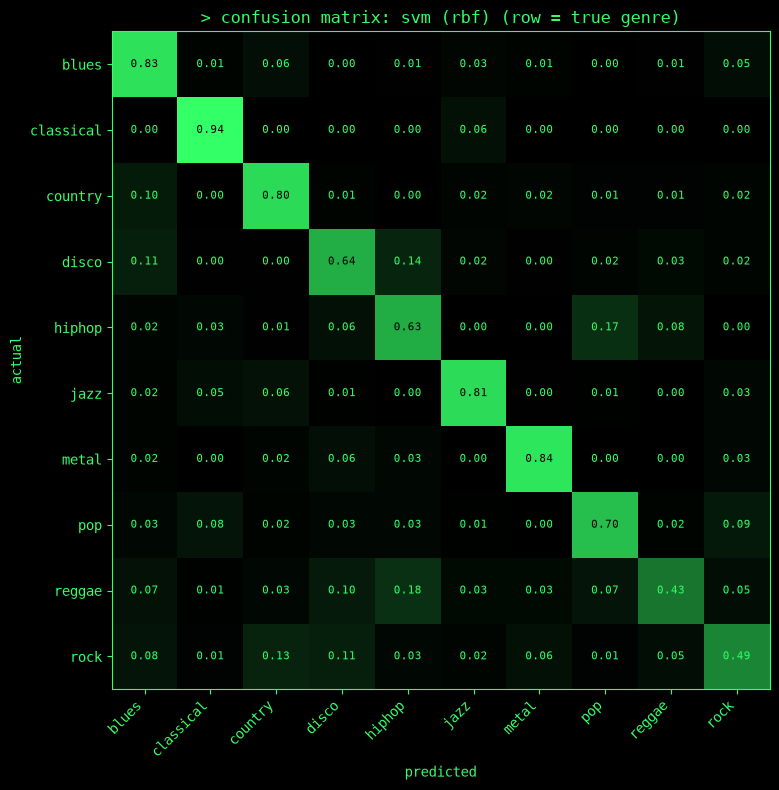

> PER-GENRE REPORT: SVM (RBF)                
┌───────────┬───────────┬────────┬──────────┐
│           │ precision │ recall │ f1-score │
├───────────┼───────────┼────────┼──────────┤
│ metal     │     0.868 │  0.844 │    0.856 │
│ classical │     0.777 │  0.938 │    0.850 │
│ jazz      │     0.832 │  0.809 │    0.820 │
│ country   │     0.761 │  0.804 │    0.782 │
│ blues     │     0.631 │  0.830 │    0.717 │
│ pop       │     0.623 │  0.700 │    0.659 │
│ disco     │     0.630 │  0.636 │    0.633 │
│ hiphop    │     0.514 │  0.631 │    0.566 │
│ rock      │     0.644 │  0.493 │    0.558 │
│ reggae    │     0.733 │  0.430 │    0.542 │
└───────────┴───────────┴────────┴──────────┘

In [8]:
cm = confusion_matrix(y_test, predictions[best_name], normalize='true')
fig, ax = plt.subplots(figsize=(9, 8))
ax.imshow(cm, cmap=LinearSegmentedColormap.from_list('terminal', ['#000000', GREEN]))
ax.grid(False)
ax.set_xticks(range(10), encoder.classes_, rotation=45, ha='right')
ax.set_yticks(range(10), encoder.classes_)
for i in range(10):
    for j in range(10):
        ax.text(j, i, f'{cm[i, j]:.2f}', ha='center', va='center', fontsize=8, color='black' if cm[i, j] > 0.5 else GREEN)
ax.set(title=f'> confusion matrix: {best_name.lower()} (row = true genre)', xlabel='predicted', ylabel='actual')
plt.tight_layout()
plt.show()

report = pd.DataFrame(classification_report(y_test, predictions[best_name], target_names=encoder.classes_, output_dict=True)).T
term_table(report.loc[encoder.classes_, ['precision', 'recall', 'f1-score']].sort_values('f1-score', ascending=False),
           f'PER-GENRE REPORT: {best_name.upper()}')

## 7. Why splitting by song matters
The same best model trained on a random clip-level split, where clips from one song can be in both sets:

In [9]:
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
leaky_acc = accuracy_score(yr_test, models[best_name].fit(Xr_train, yr_train).predict(Xr_test))
term_table(pd.DataFrame({'accuracy': [results_df.loc[best_name, 'accuracy'], leaky_acc]},
                        index=['split by song (honest)', 'random clip split (leaky)']), 'DATA LEAKAGE CHECK')

> DATA LEAKAGE CHECK                    
┌───────────────────────────┬──────────┐
│                           │ accuracy │
├───────────────────────────┼──────────┤
│ split by song (honest)    │    0.708 │
│ random clip split (leaky) │    0.913 │
└───────────────────────────┴──────────┘

## 8. Clip features vs full-song features
The dataset also has one row of features per full 30-second song (1,000 rows). How does a model trained on those compare with one trained on 3-second clips? Both are tested on the **same 200 test songs**, so the comparison is fair.

In [10]:
songs = pd.read_csv('features_30_sec.csv')
Xs = songs[feature_cols]
ys = encoder.transform(songs['label'])
songs['song'] = songs['filename'].str.rsplit('.', n=1).str[0]  # 'blues.00000.wav' -> 'blues.00000'
is_test = songs['song'].isin(set(df.song.iloc[test_idx]))
Xs_train, Xs_test, ys_train, ys_test = Xs[~is_test], Xs[is_test], ys[~is_test], ys[is_test]
assert is_test.sum() == df.song.iloc[test_idx].nunique()  # same test songs as the clip models

full_song = {}
for name in models:
    pred = models[name].fit(Xs_train, ys_train).predict(Xs_test)
    full_song[name] = accuracy_score(ys_test, pred)

compare = pd.DataFrame({'3-sec clips (800 train songs)': results_df['accuracy'],
                        '30-sec songs (800 train songs)': pd.Series(full_song)})
term_table(compare, 'ACCURACY: CLIPS VS FULL SONGS')

> ACCURACY: CLIPS VS FULL SONGS                                                          
┌──────────────────────┬───────────────────────────────┬────────────────────────────────┐
│                      │ 3-sec clips (800 train songs) │ 30-sec songs (800 train songs) │
├──────────────────────┼───────────────────────────────┼────────────────────────────────┤
│ Neural network (MLP) │                         0.685 │                          0.695 │
│ Random Forest        │                         0.690 │                          0.675 │
│ SVM (RBF)            │                         0.708 │                          0.730 │
└──────────────────────┴───────────────────────────────┴────────────────────────────────┘

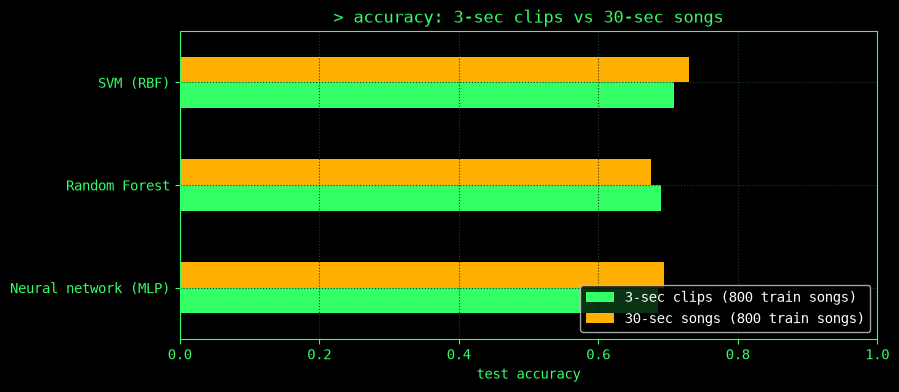

In [11]:
compare.plot(kind='barh', figsize=(9, 4), color=[GREEN, AMBER], title='> accuracy: 3-sec clips vs 30-sec songs')
plt.xlabel('test accuracy')
plt.xlim(0, 1)
plt.legend(loc='lower right')
plt.show()

## 9. Which audio features matter most?

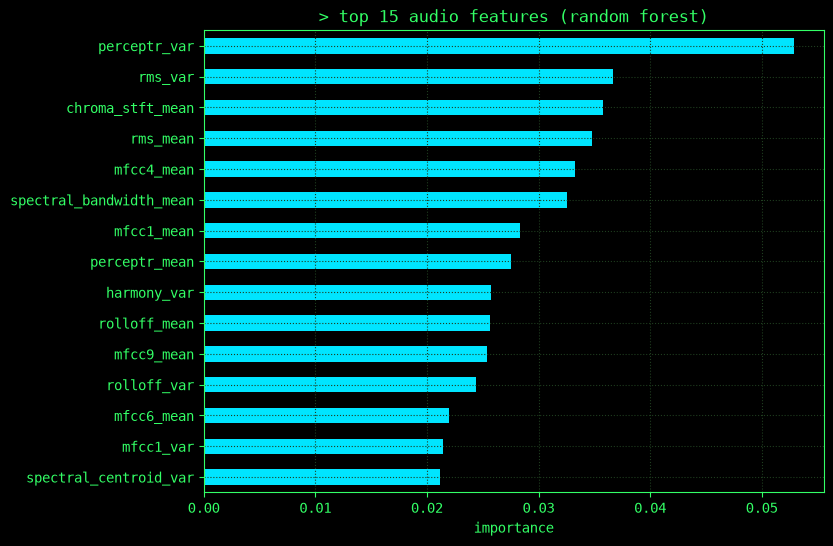

> TOP 8 FEATURES                        
┌─────────────────────────┬────────────┐
│                         │ importance │
├─────────────────────────┼────────────┤
│ perceptr_var            │      0.053 │
│ rms_var                 │      0.037 │
│ chroma_stft_mean        │      0.036 │
│ rms_mean                │      0.035 │
│ mfcc4_mean              │      0.033 │
│ spectral_bandwidth_mean │      0.033 │
│ mfcc1_mean              │      0.028 │
│ perceptr_mean           │      0.028 │
└─────────────────────────┴────────────┘

In [12]:
rf = models['Random Forest'].fit(X_train, y_train).named_steps['randomforestclassifier']
importance = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False)
importance.head(15).sort_values().plot(kind='barh', figsize=(8, 6), color=CYAN, title='> top 15 audio features (random forest)')
plt.xlabel('importance')
plt.show()
term_table(importance.head(8).to_frame('importance'), 'TOP 8 FEATURES')

## 10. Conclusions

- **Data:** 1,000 songs (100 per genre), each cut into ten 3-second clips with 57 Librosa features (MFCCs, chroma, spectral features, RMS energy, tempo). No missing values.
- **Honest split:** clips were split **by song**, so no song appears in both training and testing. A random clip-level split would report **91.3%** accuracy instead of **70.8%**, because the model partly recognises songs it has already heard rather than genres.
- **Model comparison:** SVM (RBF) is the best clip classifier (70.8% accuracy, macro F1 0.699), ahead of Random Forest (69.0%) and the MLP neural network (68.5%).
- **Song-level voting:** combining the 10 clip predictions of a song by majority vote raises accuracy to **77.5%** on 200 unseen songs.
- **Per genre:** metal, classical and jazz are the easiest (F1 0.82-0.86). Reggae, rock and hip-hop are the hardest (F1 0.54-0.57) because they share rhythm and timbre with other genres.
- **Clips vs full songs:** tested on the same 200 songs, features computed over the full 30 seconds help SVM a little (73.0% vs 70.8%) and the MLP (69.5% vs 68.5%), but not Random Forest (67.5% vs 69.0%). Voting over a song's 10 clips (77.5%) beats every full-song model.
- **Most useful features:** variance of the percussive component, RMS energy (loudness), chroma and the first MFCCs, which together describe rhythm, loudness and timbre.